# 03 · RFM Analysis

**Plain English:** we score every customer on three questions:
- **Recency:** how many days since they last bought?
- **Frequency:** how many orders have they placed?
- **Monetary:** how much have they spent in total?

Then simple, explainable rules turn those scores into segments a marketing team can act on.

**Technical:** `customer_features` builds one row per customer from transactions *before* a date
(here the day after the last sale), and `rfm_segments` adds 1-5 quintile scores and a segment.

In [1]:
import sys; sys.path.insert(0, "..")
import plotly.io as pio
pio.renderers.default = "png"  # static images so charts render on GitHub
import kaleido; kaleido.start_sync_server(silence_warnings=True)  # one shared browser for reliable PNG export
import logging, warnings
logging.getLogger("kaleido").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", message="The kopts argument")

import pandas as pd
import plotly.express as px
from src.config import CLEAN_PARQUET, FIGURES_DIR, SCORING_DATE
from src.analytics.rfm import customer_features, rfm_segments, segment_summary, SEGMENT_DESCRIPTIONS

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## 1. Build customer features

In [2]:
clean = pd.read_parquet(CLEAN_PARQUET)
customers = rfm_segments(customer_features(clean, SCORING_DATE))
print(f"{len(customers):,} customers scored as of {SCORING_DATE}")
customers[["customer_id", "recency_days", "frequency", "monetary", "r_score", "f_score", "m_score", "segment"]].head()

5,839 customers scored as of 2011-12-10


,customer_id,recency_days,frequency,monetary,r_score,f_score,m_score,segment
0,12346,529,2,169.36,1,2,1,Inactive
1,12347,2,8,4921.53,5,4,5,High-value
2,12348,75,5,1658.40,3,4,4,Loyal
3,12349,18,3,3678.69,5,3,5,Regular
4,12350,310,1,294.40,2,1,2,Inactive


## 2. What do R, F and M look like?
All three are heavily skewed: most customers buy a few times and spend modestly, while a small
group buys constantly. That skew is why we score by **quintiles** (rank-based) rather than raw values.

       recency_days  frequency  monetary
count        5839.0     5839.0    5839.0
mean          199.9        6.2    2820.6
std           208.6       12.6   13877.5
min             0.0        1.0       2.9
25%            25.0        1.0     336.2
50%            95.0        3.0     851.9
75%           379.0        7.0    2206.5
max           738.0      369.0  579128.6


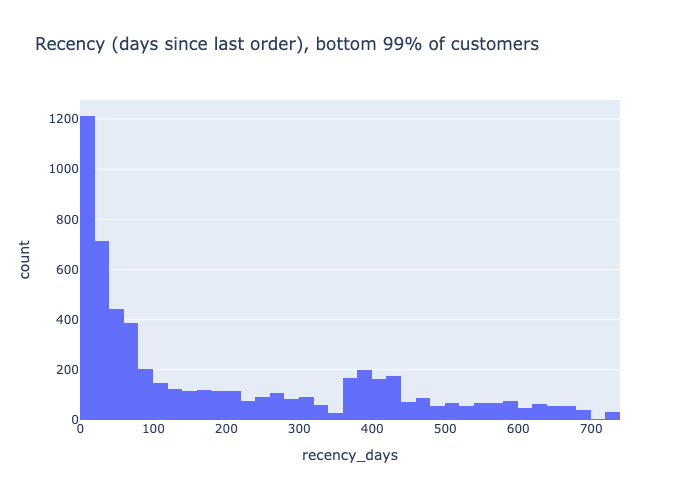

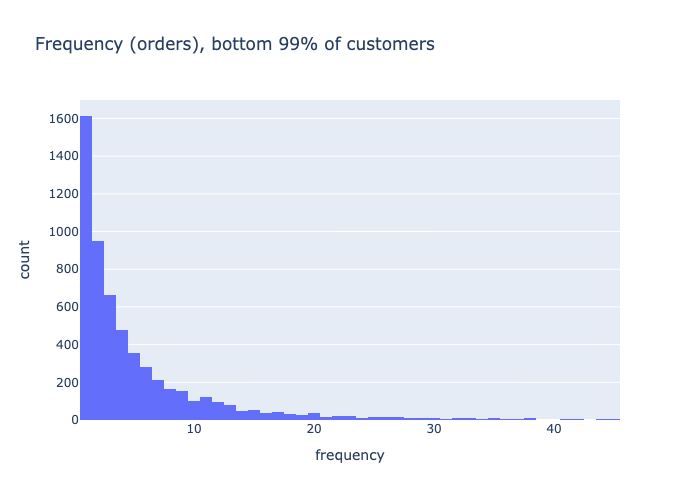

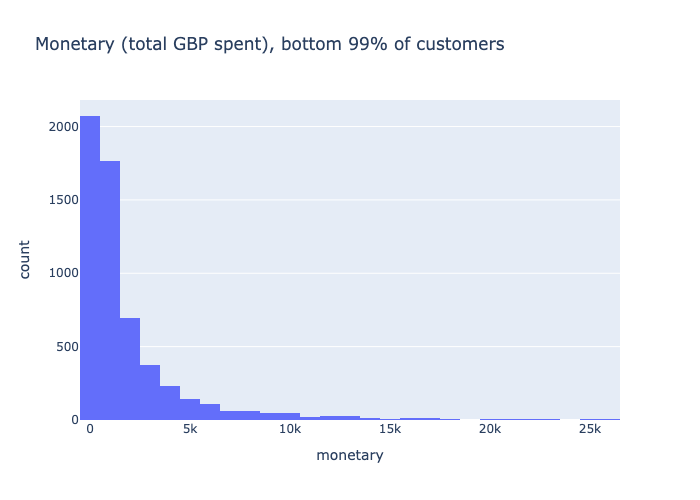

In [3]:
print(customers[["recency_days", "frequency", "monetary"]].describe().round(1).to_string())
for col, title in [("recency_days", "Recency (days since last order)"),
                   ("frequency", "Frequency (orders)"),
                   ("monetary", "Monetary (total GBP spent)")]:
    upper = customers[col].quantile(0.99)
    px.histogram(customers[customers[col] <= upper], x=col, nbins=50,
                 title=f"{title}, bottom 99% of customers").show()

## 3. Segment rules
Scores run 1 (worst) to 5 (best); for recency, 5 means *most recent*. Rules are checked in order:

| Segment | Rule |
|---|---|
| High-value | R, F and M all >= 4 |
| Loyal | F >= 4 and R >= 3 |
| New | first purchase within the last 90 days |
| At-risk | R <= 2 but F or M >= 3 |
| Inactive | R <= 2 otherwise |
| Regular | everyone else |

## 4. Segment summary

In [4]:
summary = segment_summary(customers)
summary["what_it_means"] = summary["segment"].map(SEGMENT_DESCRIPTIONS)
summary.style.format({"avg_recency_days": "{:.0f}", "avg_frequency": "{:.1f}", "avg_monetary": "{:,.0f}",
                      "total_revenue": "{:,.0f}", "revenue_share": "{:.1%}", "customer_share": "{:.1%}"})

,segment,customers,avg_recency_days,avg_frequency,avg_monetary,total_revenue,revenue_share,customer_share,what_it_means
0,High-value,1254,19,17.2,"9,066","11,369,340",69.0%,21.5%,"Bought recently, buy often and spend the most. Protect and reward them."
1,At-risk,984,376,4.4,"1,761","1,733,035",10.5%,16.9%,"Used to buy often or spend a lot, but haven't bought in a while. Win them back now."
2,Loyal,595,85,8.2,"2,851","1,696,159",10.3%,10.2%,"Buy often and are still active, but spend less than the top tier. Upsell them."
3,Regular,1094,74,2.7,929,"1,016,433",6.2%,18.7%,Average on every dimension. Keep engaged with standard marketing.
4,Inactive,1351,460,1.2,255,"344,998",2.1%,23.1%,"Bought rarely, spent little, and not recently. Low-cost reactivation only."
5,New,561,35,1.5,552,"309,730",1.9%,9.6%,First purchase within the last 90 days. Onboard them toward a second order.


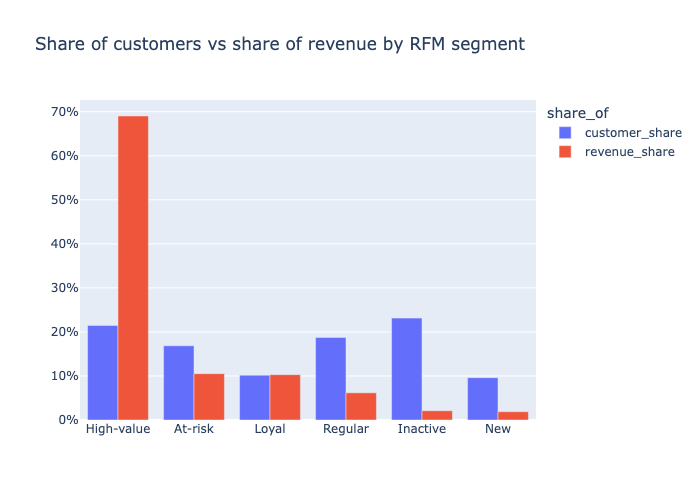

High-value: 21.5% of customers generate 69.0% of revenue.


In [5]:
long = summary.melt(id_vars="segment", value_vars=["customer_share", "revenue_share"],
                    var_name="share_of", value_name="share")
fig = px.bar(long, x="segment", y="share", color="share_of", barmode="group",
             title="Share of customers vs share of revenue by RFM segment",
             labels={"share": "", "segment": ""})
fig.update_yaxes(tickformat=".0%")
fig.write_image(FIGURES_DIR / "rfm_segments.png", width=1000, height=450)
fig.show()
top = summary.iloc[0]
print(f"{top['segment']}: {top['customer_share']:.1%} of customers generate {top['revenue_share']:.1%} of revenue.")

## 5. Business meaning

In [6]:
pd.DataFrame(SEGMENT_DESCRIPTIONS.items(), columns=["segment", "recommended action"])

,segment,recommended action
0,High-value,"Bought recently, buy often and spend the most...."
1,Loyal,"Buy often and are still active, but spend less..."
2,New,First purchase within the last 90 days. Onboar...
3,At-risk,"Used to buy often or spend a lot, but haven't ..."
4,Inactive,"Bought rarely, spent little, and not recently...."
5,Regular,Average on every dimension. Keep engaged with ...


**Takeaway:** revenue is concentrated in a small group of customers, so protecting them matters most,
while the At-risk group is the clearest win-back opportunity (they have spent before but stopped).
The exact shares are printed above.